# Extracting Data

In [1]:
import pandas as pd
from spacepy import pycdf
import numpy as np
from scipy.signal import butter, filtfilt
from scipy.linalg import eig
import matplotlib.pyplot as plt

# Load the CDF file
cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
cdf = pycdf.CDF(cdf_path)
cdf

<CDF:
Epoch: CDF_TIME_TT2000 [1051008]
Epoch_state: CDF_TIME_TT2000 [2883]
label_b_bcs: CDF_CHAR*10 [4] NRV
label_b_dmpa: CDF_CHAR*10 [4] NRV
label_b_gse: CDF_CHAR*10 [4] NRV
label_b_gsm: CDF_CHAR*11 [4] NRV
label_r_gse: CDF_CHAR*10 [4] NRV
label_r_gsm: CDF_CHAR*10 [4] NRV
mms1_fgm_b_bcs_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_dmpa_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gse_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_b_gsm_srvy_l2: CDF_REAL4 [1051008, 4]
mms1_fgm_bdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_etemp_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_flag_srvy_l2: CDF_UINT4 [1051008]
mms1_fgm_hirange_srvy_l2: CDF_UINT1 [1051008]
mms1_fgm_mode_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_r_gse_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_r_gsm_srvy_l2: CDF_REAL4 [2883, 4]
mms1_fgm_rdeltahalf_srvy_l2: CDF_FLOAT [1051008]
mms1_fgm_stemp_srvy_l2: CDF_FLOAT [1051008]
represent_vec_tot: CDF_CHAR*1 [4] NRV
>

In [2]:
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt

# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
B_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
B_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
B_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]

# Combine the data into a DataFrame
data = pd.DataFrame({'datetime': datetime, 'B_x': B_x, 'B_y': B_y, 'B_z': B_z}).set_index('datetime')

# Define the bandpass filter function
def bandpass_filter(data, lowcut, highcut, sampling_freq, order=4):
    nyquist = 0.5 * sampling_freq
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# Calculate the sampling frequency
time_diff = np.diff(datetime.values.astype('datetime64[ns]').astype(float)) / 1e9  # Convert to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz

# Define the bandpass filter frequency range
lowcut = 0.05  # Hz
highcut = 5    # Hz

# Apply the bandpass filter to each magnetic field component
data['B_x_f'] = bandpass_filter(data['B_x'].values, lowcut, highcut, sampling_freq)
data['B_y_f'] = bandpass_filter(data['B_y'].values, lowcut, highcut, sampling_freq)
data['B_z_f'] = bandpass_filter(data['B_z'].values, lowcut, highcut, sampling_freq)

# Select the filtered data within the specified time range
start_time = pd.Timestamp('2015-10-28 16:45:03.260000')
end_time = pd.Timestamp('2015-10-28 16:45:06.385100')
filtered_data = data.loc[start_time:end_time]

# Calculate mean values for the filtered components
m1, m2, m3 = filtered_data[['B_x_f', 'B_y_f', 'B_z_f']].mean()

# Manually calculate the covariance matrix components
M11 = np.mean((filtered_data['B_x_f'] - m1) * (filtered_data['B_x_f'] - m1))
M12 = np.mean((filtered_data['B_x_f'] - m1) * (filtered_data['B_y_f'] - m2))
M13 = np.mean((filtered_data['B_x_f'] - m1) * (filtered_data['B_z_f'] - m3))

M21 = M12
M22 = np.mean((filtered_data['B_y_f'] - m2) * (filtered_data['B_y_f'] - m2))
M23 = np.mean((filtered_data['B_y_f'] - m2) * (filtered_data['B_z_f'] - m3))

M31 = M13
M32 = M23
M33 = np.mean((filtered_data['B_z_f'] - m3) * (filtered_data['B_z_f'] - m3))

# Construct the covariance matrix manually
M = np.array([[M11, M12, M13],
              [M21, M22, M23],
              [M31, M32, M33]])

# Calculate eigenvalues and eigenvectors manually
eig_vals, eig_vecs = np.linalg.eig(M)

# Sorting eigenvalues and corresponding eigenvectors
sorted_indices = np.argsort(eig_vals)[::-1]
eig_vals = eig_vals[sorted_indices]
eig_vecs = eig_vecs[:, sorted_indices]

In [3]:
filtered_data

,B_x,B_y,B_z,B_x_f,B_y_f,B_z_f
datetime,,,,,,
2015-10-28 16:45:03.260066,14.672593,13.518611,44.026421,-0.134378,0.102147,0.066799
2015-10-28 16:45:03.385067,14.856996,13.540720,43.975670,0.059912,0.127012,0.010724
2015-10-28 16:45:03.510069,15.012718,13.550757,43.905437,0.214906,0.133647,-0.063168
2015-10-28 16:45:03.635071,15.146096,13.542490,43.847641,0.360793,0.130082,-0.124292
2015-10-28 16:45:03.760073,15.287401,13.555379,43.808395,0.497739,0.137811,-0.168819
2015-10-28 16:45:03.885074,15.364053,13.540406,43.768734,0.590407,0.128720,-0.211165
2015-10-28 16:45:04.010076,15.422673,13.506946,43.746273,0.642195,0.089741,-0.238225
2015-10-28 16:45:04.135078,15.420465,13.459889,43.746998,0.656286,0.047979,-0.242335
2015-10-28 16:45:04.260079,15.407124,13.421785,43.754776,0.638269,0.005854,-0.235840


# Putting Time Range and Finding Covariance Matrix

In [4]:

# # Create the covariance matrix
# M = np.array([[M11, M12, M13],
#               [M21, M22, M23],
#               [M31, M32, M33]])


# # Calculate eigenvalues and eigenvectors
# vals, vecs = eig(M)
# vals = np.real(vals)
# vecs = np.real(vecs)

# # Sort eigenvalues and corresponding eigenvectors
# sorted_indices = np.argsort(vals)[::-1]
# eig_vals = vals[sorted_indices]
# eig_vecs = vecs[:, sorted_indices]

# Correct eigenvector orientations
X = np.cross(eig_vecs[:, 0], eig_vecs[:, 1])
Y = eig_vecs[:, 2]
# ensures that the eigenvectors form a right-handed coordinate system by verifying the orientation of the third eigenvector.
if not np.array_equal(X, Y): 
    eig_vecs[:, 1] *= -1     # The reason for flipping both is to preserve the orthogonality while ensuring a right-handed system. 
    eig_vecs[:, 2] *= -1     # This approach preserves orthogonality and orientation consistency in all cases. 
                             #  It ensures that the determinant of eig_vecs remains positive (which is crucial for a valid rotation matrix).

# Perform MVA using filtered data
mva_matrix = np.dot(filtered_data[['B_x_f', 'B_y_f', 'B_z_f']], eig_vecs)
filtered_data['B_L'] = mva_matrix[:, 0]
filtered_data['B_M'] = mva_matrix[:, 1]
filtered_data['B_N'] = mva_matrix[:, 2]
# filtered_data['B_total'] = np.sqrt(
#     filtered_data['B_L']**2 + filtered_data['B_M']**2 + filtered_data['B_N']**2
# )



/tmp/ipykernel_3087/4113298977.py:28: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data['B_L'] = mva_matrix[:, 0]
/tmp/ipykernel_3087/4113298977.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data['B_M'] = mva_matrix[:, 1]
/tmp/ipykernel_3087/4113298977.py:30: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/s

#  Eigen vectors

In [5]:
eig_vecs

array([[ 0.92560574,  0.0673385 , -0.37245071],
       [ 0.12119596, -0.98496428,  0.12311337],
       [-0.35856038, -0.15909396, -0.91984975]])

# Eigen Values

In [6]:
eig_vals

array([2.45379550e-01, 1.23129259e-02, 7.41225016e-05])

In [7]:
eig_vals[0]/eig_vals[1]

np.float64(19.928614206279086)

In [8]:
eig_vals[2]/eig_vals[1]

np.float64(0.0060198934116391396)

In [9]:
eig_vals[1]/eig_vals[2]

np.float64(166.1158980101797)

In [10]:
eig_vals

array([2.45379550e-01, 1.23129259e-02, 7.41225016e-05])

In [11]:
eig_vecs[0]/eig_vecs[1]

array([ 7.63726563, -0.06836644, -3.02526615])

In [12]:
# import plotly.subplots as sp
# import plotly.graph_objects as go

# # Create subplots
# fig = sp.make_subplots(rows=2, cols=1, shared_xaxes=True, subplot_titles=(
#     "Original Magnetic Field Components (GSE)", 
#     "Magnetic Field Components in MVA Coordinate System"))

# # First subplot: Original magnetic field components
# fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_x'], mode='lines', name='B_x', line=dict(color='blue')), row=1, col=1)
# fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_y'], mode='lines', name='B_y', line=dict(color='orange')), row=1, col=1)
# fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_z'], mode='lines', name='B_z', line=dict(color='green')), row=1, col=1)

# # Second subplot: MVA magnetic field components
# fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_L'], mode='lines', name='B_L', line=dict(color='blue')), row=2, col=1)
# fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_M'], mode='lines', name='B_M', line=dict(color='orange')), row=2, col=1)
# fig.add_trace(go.Scatter(x=filtered_data.index, y=filtered_data['B_N'], mode='lines', name='B_N', line=dict(color='green')), row=2, col=1)

# fig.update_layout(
#     title={
#         'text': "Magnetic Field Data",  # Title text
#         'x': 0.5,  # Center the title horizontally
#         'xanchor': 'center',  # Center align the title
#         'yanchor': 'top',  # Keep the title at the top
#         'y': 0.95  # Adjust vertical positioning
#     },
#     xaxis_title="Time",
#     yaxis_title="Magnetic Field (nT)",
#     yaxis_title_standoff=20,  # Adjusts distance of y-axis title from the axis
#     height=400,
#     template='plotly_white'  # Optional for a clean look
# )


# fig.show()


In [13]:
filtered_data

,B_x,B_y,B_z,B_x_f,B_y_f,B_z_f,B_L,B_M,B_N
datetime,,,,,,,,,
2015-10-28 16:45:03.260066,14.672593,13.518611,44.026421,-0.134378,0.102147,0.066799,-0.135952,-0.120287,0.001180
2015-10-28 16:45:03.385067,14.856996,13.540720,43.975670,0.059912,0.127012,0.010724,0.067002,-0.122774,-0.016542
2015-10-28 16:45:03.510069,15.012718,13.550757,43.905437,0.214906,0.133647,-0.063168,0.237766,-0.107117,-0.005483
2015-10-28 16:45:03.635071,15.146096,13.542490,43.847641,0.360793,0.130082,-0.124292,0.394284,-0.084057,-0.004032
2015-10-28 16:45:03.760073,15.287401,13.555379,43.808395,0.497739,0.137811,-0.168819,0.537944,-0.075364,-0.013129
2015-10-28 16:45:03.885074,15.364053,13.540406,43.768734,0.590407,0.128720,-0.211165,0.637800,-0.053433,-0.009810
2015-10-28 16:45:04.010076,15.422673,13.506946,43.746273,0.642195,0.089741,-0.238225,0.690713,-0.007247,-0.009007
2015-10-28 16:45:04.135078,15.420465,13.459889,43.746998,0.656286,0.047979,-0.242335,0.700168,0.035490,-0.015616
2015-10-28 16:45:04.260079,15.407124,13.421785,43.754776,0.638269,0.005854,-0.235840,0.676058,0.074734,-0.020066


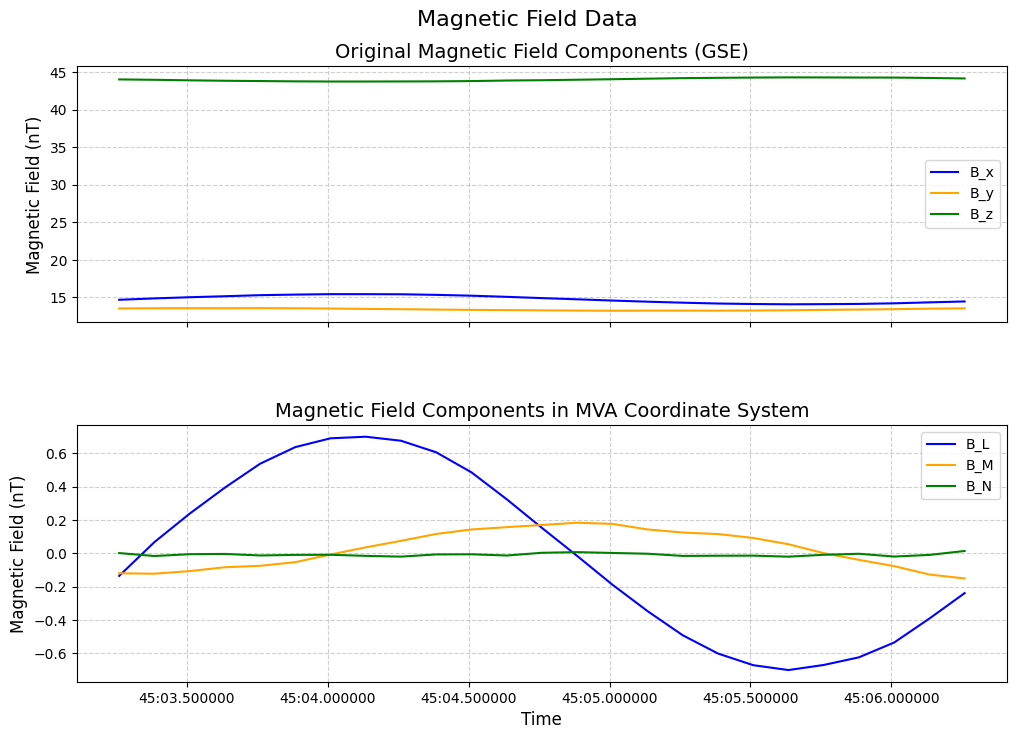

In [14]:
import matplotlib.pyplot as plt

# Create a figure with two subplots
fig, axs = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# First subplot: Original Magnetic Field Components (GSE)
axs[0].plot(filtered_data.index, filtered_data['B_x'], label='B_x', color='blue')
axs[0].plot(filtered_data.index, filtered_data['B_y'], label='B_y', color='orange')
axs[0].plot(filtered_data.index, filtered_data['B_z'], label='B_z', color='green')
axs[0].set_title("Original Magnetic Field Components (GSE)", fontsize=14)
axs[0].set_ylabel("Magnetic Field (nT)", fontsize=12)
axs[0].grid(True, linestyle='--', alpha=0.6)
axs[0].legend()

# Second subplot: Magnetic Field Components in MVA Coordinate System
axs[1].plot(filtered_data.index, filtered_data['B_L'], label='B_L', color='blue')
axs[1].plot(filtered_data.index, filtered_data['B_M'], label='B_M', color='orange')
axs[1].plot(filtered_data.index, filtered_data['B_N'], label='B_N', color='green')
axs[1].set_title("Magnetic Field Components in MVA Coordinate System", fontsize=14)
axs[1].set_xlabel("Time", fontsize=12)
axs[1].set_ylabel("Magnetic Field (nT)", fontsize=12)
axs[1].grid(True, linestyle='--', alpha=0.6)
axs[1].legend()

# Set a global title for the figure
fig.suptitle("Magnetic Field Data", fontsize=16, y=0.95)  # Adjust y for vertical placement
plt.subplots_adjust(hspace=0.4)  # Adjust space between subplots

# Show the plot
plt.show()


In [15]:
filtered_data['B_N']

datetime
2015-10-28 16:45:03.260066    0.001180
2015-10-28 16:45:03.385067   -0.016542
2015-10-28 16:45:03.510069   -0.005483
2015-10-28 16:45:03.635071   -0.004032
2015-10-28 16:45:03.760073   -0.013129
2015-10-28 16:45:03.885074   -0.009810
2015-10-28 16:45:04.010076   -0.009007
2015-10-28 16:45:04.135078   -0.015616
2015-10-28 16:45:04.260079   -0.020066
2015-10-28 16:45:04.385081   -0.006960
2015-10-28 16:45:04.510083   -0.006085
2015-10-28 16:45:04.635084   -0.013463
2015-10-28 16:45:04.760086    0.002941
2015-10-28 16:45:04.885088    0.006853
2015-10-28 16:45:05.010090    0.001910
2015-10-28 16:45:05.135091   -0.002789
2015-10-28 16:45:05.260093   -0.015874
2015-10-28 16:45:05.385095   -0.014779
2015-10-28 16:45:05.510096   -0.014235
2015-10-28 16:45:05.635098   -0.020389
2015-10-28 16:45:05.760100   -0.009088
2015-10-28 16:45:05.885101   -0.002999
2015-10-28 16:45:06.010103   -0.019678
2015-10-28 16:45:06.135105   -0.009846
2015-10-28 16:45:06.260107    0.013759
Name: B_N, dtype

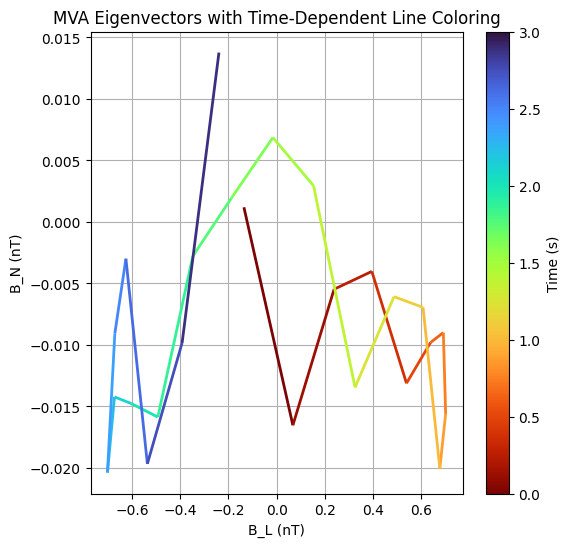

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

# Convert time to numeric for normalization
time_numeric = (filtered_data.index - filtered_data.index[0]).total_seconds()

# Prepare the data for the line segments
x = filtered_data['B_L'].values
y = filtered_data['B_N'].values

# Create segments for the line plot
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='turbo_r', norm=norm)
lc.set_array(time_numeric)  # Use the numeric time for color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()  # Adjust axis limits to fit the line
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_N (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()


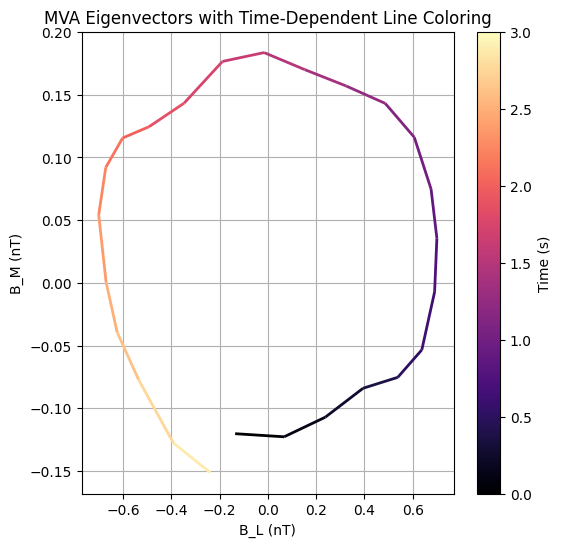

In [17]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

# Convert time to numeric for normalization
time_numeric = (filtered_data.index - filtered_data.index[0]).total_seconds()

# Prepare the data for the line segments
x = filtered_data['B_L'].values
y = filtered_data['B_M'].values

# Create segments for the line plot
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='magma', norm=norm)
lc.set_array(time_numeric)  # Use the numeric time for color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()  # Adjust axis limits to fit the line
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_M (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()


In [18]:
len(filtered_data['B_L'])

25

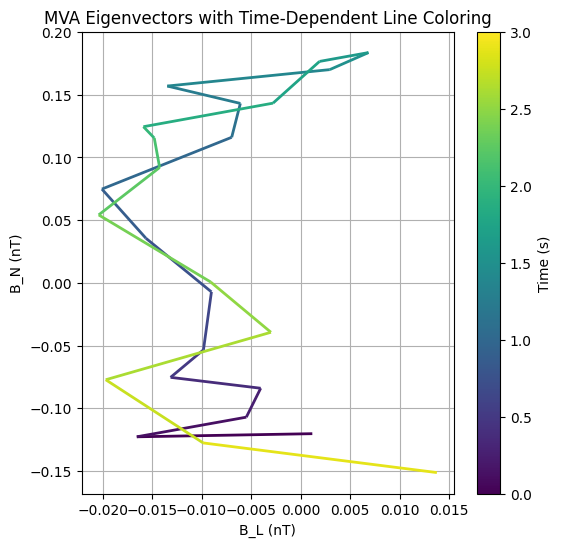

In [19]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

# Convert time to numeric for normalization
time_numeric = (filtered_data.index - filtered_data.index[0]).total_seconds()

# Prepare the data for the line segments
x = filtered_data['B_N'].values
y = filtered_data['B_M'].values

# Create segments for the line plot
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='viridis', norm=norm)
lc.set_array(time_numeric)  # Use the numeric time for color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()  # Adjust axis limits to fit the line
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_N (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()


In [20]:
import pandas as pd
from spacepy import pycdf
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt


# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
b_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
b_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
b_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]
b_t = cdf['mms1_fgm_b_gse_srvy_l2'][:, 3]

# Create DataFrame
df = pd.DataFrame({'datetime': datetime, 'b_x': b_x, 'b_y': b_y, 'b_z': b_z, 'b_t': b_t}).set_index('datetime')

# Compute Sampling Frequency
time_diff = np.diff(df.index.astype('int64')) / 1e9  # Convert nanoseconds to seconds
fs = 1 / np.mean(time_diff)  # Hz

# Define Butterworth Low-Pass Filter
def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs  # Nyquist Frequency
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    return filtfilt(b, a, data)  # Use filtfilt for zero-phase filtering

# Apply Low-Pass Filter
cutoff_freq = 0.05  # Hz
df['B0_x'] = butter_lowpass_filter(df['b_x'], cutoff_freq, fs)
df['B0_y'] = butter_lowpass_filter(df['b_y'], cutoff_freq, fs)
df['B0_z'] = butter_lowpass_filter(df['b_z'], cutoff_freq, fs)
df['B0_t'] = butter_lowpass_filter(df['b_t'], cutoff_freq, fs)


# Select the filtered data within the specified time range
start_time = pd.Timestamp('2015-10-28 16:45:03.255000')
end_time = pd.Timestamp('2015-10-28 16:45:06.385000')
# filtered_data = data.loc[start_time:end_time]
# # Define time range
# start_time = pd.Timestamp('2015-10-28 13:00:00')
# end_time = pd.Timestamp('2015-10-28 17:30:00')

# # Filter dataframe for plotting
df_filtered = df.loc[start_time:end_time]



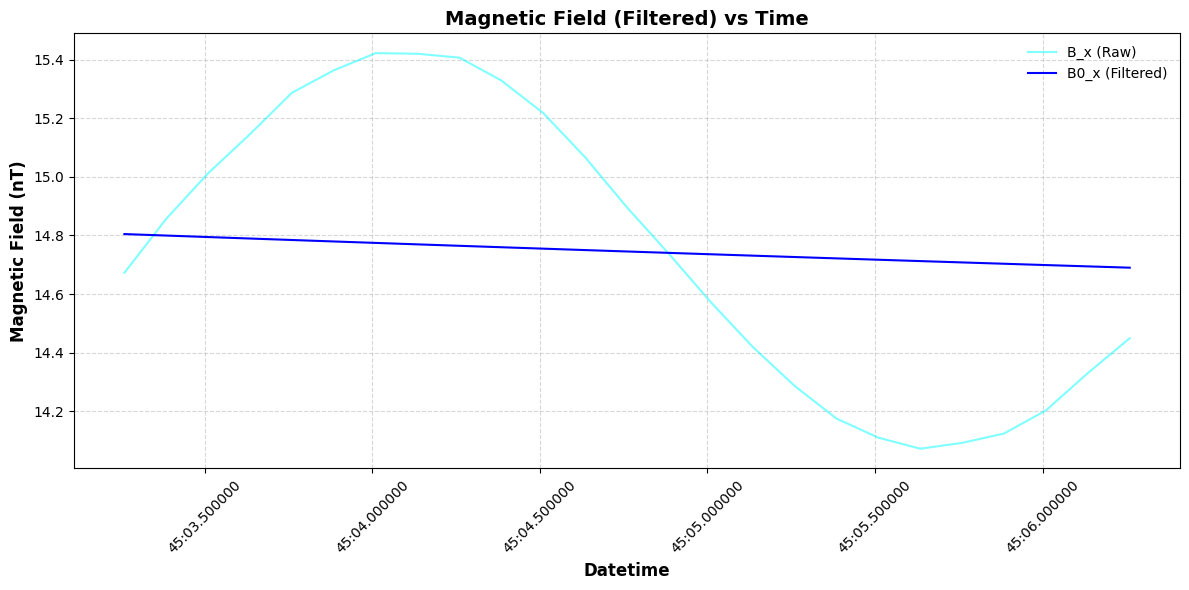

In [21]:
plt.figure(figsize=(12, 6))
plt.plot(df_filtered.index, df_filtered['b_x'], label='B_x (Raw)', color='cyan', alpha=0.5)
plt.plot(df_filtered.index, df_filtered['B0_x'], label='B0_x (Filtered)', color='blue')
# Labels, title, and formatting
plt.xlabel('Datetime', fontsize=12, fontweight='bold')
plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
plt.title('Magnetic Field (Filtered) vs Time', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)
plt.grid(linestyle='--', alpha=0.5)
plt.legend(frameon=False, fontsize=10)
plt.tight_layout()
plt.show()


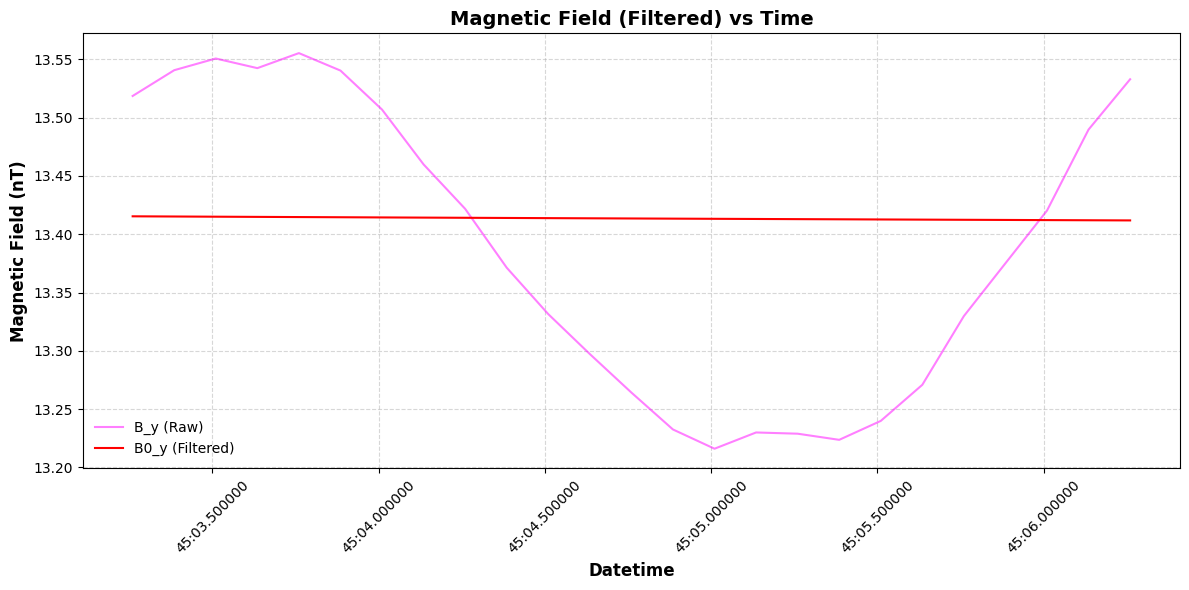

In [22]:
plt.figure(figsize=(12, 6))
plt.plot(df_filtered.index, df_filtered['b_y'], label='B_y (Raw)', color='magenta', alpha=0.5)
plt.plot(df_filtered.index, df_filtered['B0_y'], label='B0_y (Filtered)', color='red')
# Labels, title, and formatting
plt.xlabel('Datetime', fontsize=12, fontweight='bold')
plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
plt.title('Magnetic Field (Filtered) vs Time', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)
plt.grid(linestyle='--', alpha=0.5)
plt.legend(frameon=False, fontsize=10)
plt.tight_layout()
plt.show()


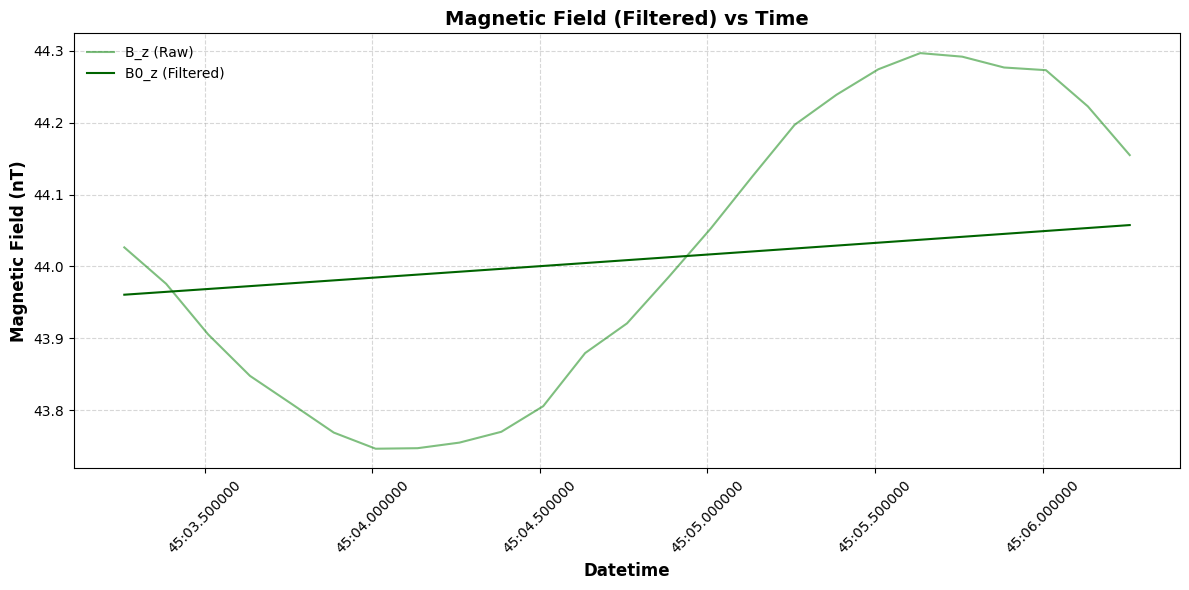

In [23]:
plt.figure(figsize=(12, 6))
plt.plot(df_filtered.index, df_filtered['b_z'], label='B_z (Raw)', color='green', alpha=0.5)
plt.plot(df_filtered.index, df_filtered['B0_z'], label='B0_z (Filtered)', color='darkgreen')

# Labels, title, and formatting
plt.xlabel('Datetime', fontsize=12, fontweight='bold')
plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
plt.title('Magnetic Field (Filtered) vs Time', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)
plt.grid(linestyle='--', alpha=0.5)
plt.legend(frameon=False, fontsize=10)
plt.tight_layout()
plt.show()


In [24]:
Bx0,By0,Bz0 = np.mean(df_filtered['B0_x']),np.mean(df_filtered['B0_y']),np.mean(df_filtered['B0_z'])
Bx0,By0, Bz0

(np.float64(14.745973326262948),
 np.float64(13.413550681488493),
 np.float64(44.00878574523771))

In [25]:
B0 = np.array([Bx0,By0,Bz0])
K = eig_vecs[:,2]

In [26]:
import numpy as np

# Compute the angle (convert to degrees)
theta = np.degrees(np.arccos(np.dot(K,B0) / (np.linalg.norm(K) * np.linalg.norm(B0))))

print(f"Angle θ between K and B0: {theta:.2f} degrees")


Angle θ between K and B0: 156.55 degrees


In [27]:
filtered_data

,B_x,B_y,B_z,B_x_f,B_y_f,B_z_f,B_L,B_M,B_N
datetime,,,,,,,,,
2015-10-28 16:45:03.260066,14.672593,13.518611,44.026421,-0.134378,0.102147,0.066799,-0.135952,-0.120287,0.001180
2015-10-28 16:45:03.385067,14.856996,13.540720,43.975670,0.059912,0.127012,0.010724,0.067002,-0.122774,-0.016542
2015-10-28 16:45:03.510069,15.012718,13.550757,43.905437,0.214906,0.133647,-0.063168,0.237766,-0.107117,-0.005483
2015-10-28 16:45:03.635071,15.146096,13.542490,43.847641,0.360793,0.130082,-0.124292,0.394284,-0.084057,-0.004032
2015-10-28 16:45:03.760073,15.287401,13.555379,43.808395,0.497739,0.137811,-0.168819,0.537944,-0.075364,-0.013129
2015-10-28 16:45:03.885074,15.364053,13.540406,43.768734,0.590407,0.128720,-0.211165,0.637800,-0.053433,-0.009810
2015-10-28 16:45:04.010076,15.422673,13.506946,43.746273,0.642195,0.089741,-0.238225,0.690713,-0.007247,-0.009007
2015-10-28 16:45:04.135078,15.420465,13.459889,43.746998,0.656286,0.047979,-0.242335,0.700168,0.035490,-0.015616
2015-10-28 16:45:04.260079,15.407124,13.421785,43.754776,0.638269,0.005854,-0.235840,0.676058,0.074734,-0.020066


In [28]:
# import pandas as pd
# from spacepy import pycdf
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.signal import butter, filtfilt



# # Load the CDF file
# cdf_path = '/home/draksha/pydata/mms1/fgm/srvy/l2/2015/10/mms1_fgm_srvy_l2_20151028_v4.18.0.cdf'
# cdf = pycdf.CDF(cdf_path)

# # Extract the magnetic field data and timestamps
# datetime = pd.to_datetime(cdf['Epoch'][:])
# b_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
# b_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
# b_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]
# b_t = cdf['mms1_fgm_b_gse_srvy_l2'][:, 3]

# # Create DataFrame
# df = pd.DataFrame({'datetime': datetime, 'b_x': b_x, 'b_y': b_y, 'b_z': b_z, 'b_t': b_t}).set_index('datetime')

# # Compute Sampling Frequency
# time_diff = np.diff(df.index.astype('int64')) / 1e9  # Convert nanoseconds to seconds
# fs = 1 / np.mean(time_diff)  # Hz

# # Define Butterworth Low-Pass Filter
# def butter_lowpass(cutoff, fs, order=4):
#     nyq = 0.5 * fs  # Nyquist Frequency
#     normal_cutoff = cutoff / nyq
#     b, a = butter(order, normal_cutoff, btype='low', analog=False)
#     return b, a

# def butter_lowpass_filter(data, cutoff, fs, order=4):
#     b, a = butter_lowpass(cutoff, fs, order=order)
#     return filtfilt(b, a, data)  # Use filtfilt for zero-phase filtering

# # Apply Low-Pass Filter
# cutoff_freq = 0.05  # Hz
# df['B0_x'] = butter_lowpass_filter(df['b_x'], cutoff_freq, fs)
# df['B0_y'] = butter_lowpass_filter(df['b_y'], cutoff_freq, fs)
# df['B0_z'] = butter_lowpass_filter(df['b_z'], cutoff_freq, fs)
# df['B0_t'] = butter_lowpass_filter(df['b_t'], cutoff_freq, fs)


# # Select the filtered data within the specified time range
# start_time = pd.Timestamp('2015-10-28 16:45:03.255000')
# end_time = pd.Timestamp('2015-10-28 16:45:06.385000')
# # filtered_data = data.loc[start_time:end_time]
# # # Define time range
# # start_time = pd.Timestamp('2015-10-28 13:00:00')
# # end_time = pd.Timestamp('2015-10-28 17:30:00')

# # # Filter dataframe for plotting
# df_filtered = df.loc[start_time:end_time]

# # Plot original vs. filtered magnetic field data
# plt.figure(figsize=(12, 6))
# plt.plot(df_filtered.index, df_filtered['b_x'], label='B_x (Raw)', color='cyan', alpha=0.5)
# plt.plot(df_filtered.index, df_filtered['B0_x'], label='B0_x (Filtered)', color='blue')
# plt.plot(df_filtered.index, df_filtered['b_y'], label='B_y (Raw)', color='magenta', alpha=0.5)
# plt.plot(df_filtered.index, df_filtered['B0_y'], label='B0_y (Filtered)', color='red')
# plt.plot(df_filtered.index, df_filtered['b_z'], label='B_z (Raw)', color='green', alpha=0.5)
# plt.plot(df_filtered.index, df_filtered['B0_z'], label='B0_z (Filtered)', color='darkgreen')

# # Labels, title, and formatting
# plt.xlabel('Datetime', fontsize=12, fontweight='bold')
# plt.ylabel('Magnetic Field (nT)', fontsize=12, fontweight='bold')
# plt.title('Magnetic Field (Filtered) vs Time', fontsize=14, fontweight='bold')
# plt.xticks(rotation=45, fontsize=10)
# plt.yticks(fontsize=10)
# plt.grid(linestyle='--', alpha=0.5)
# plt.legend(frameon=False, fontsize=10)
# plt.tight_layout()
# plt.show()


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
B_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
B_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
B_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]

# Combine the data into a DataFrame and remove NaN values
data = pd.DataFrame({'datetime': datetime, 'B_x': B_x, 'B_y': B_y, 'B_z': B_z}).set_index('datetime')
data.dropna(inplace=True)

# Define the bandpass filter function
def bandpass_filter(data, lowcut, highcut, sampling_freq, order=4):
    nyquist = 0.5 * sampling_freq
    low, high = lowcut / nyquist, highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data, padtype='odd')  # Edge handling with 'odd' padding

# Calculate the sampling frequency
time_diff = np.diff(data.index.values.astype('datetime64[ns]').astype(float)) / 1e9  # Convert to seconds
sampling_freq = 1 / np.mean(time_diff)  # Hz

# Define the bandpass filter frequency range
lowcut, highcut = 0.05, 5  # Hz

# Apply the bandpass filter to each magnetic field component
data['B_x_f'] = bandpass_filter(data['B_x'].values, lowcut, highcut, sampling_freq)
data['B_y_f'] = bandpass_filter(data['B_y'].values, lowcut, highcut, sampling_freq)
data['B_z_f'] = bandpass_filter(data['B_z'].values, lowcut, highcut, sampling_freq)

# Select the filtered data within the specified time range
start_time, end_time = pd.Timestamp('2015-10-28 16:45:03.260000'), pd.Timestamp('2015-10-28 16:45:06.385100')
filtered_data = data[(data.index >= start_time) & (data.index <= end_time)]

# Compute mean values for filtered components
m1, m2, m3 = filtered_data[['B_x_f', 'B_y_f', 'B_z_f']].mean()

# Manually calculate the covariance matrix components
M = np.cov(filtered_data[['B_x_f', 'B_y_f', 'B_z_f']].values.T)

# # Compute eigenvalues and eigenvectors using SVD for better numerical stability
# U, S, _ = np.linalg.svd(M)
# eig_vals, eig_vecs = S, U


eig_vals , eig_vecs = np.linalg.eigh(M)
# Ensure a right-handed coordinate system
X = np.cross(eig_vecs[:, 0], eig_vecs[:, 1])
if np.dot(X, eig_vecs[:, 2]) < 0:
    # eig_vecs[:, 1] *= -1
    eig_vecs[:, 2] *= -1

# Transform the magnetic field data into the MVA coordinate system
mva_matrix = np.dot(filtered_data[['B_x_f', 'B_y_f', 'B_z_f']], eig_vecs)
filtered_data[['B_L', 'B_M', 'B_N']] = mva_matrix

# Plot the transformed magnetic field data
time_numeric = (filtered_data.index - filtered_data.index[0]).total_seconds()




/tmp/ipykernel_3087/2286957260.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data[['B_L', 'B_M', 'B_N']] = mva_matrix
/tmp/ipykernel_3087/2286957260.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data[['B_L', 'B_M', 'B_N']] = mva_matrix
/tmp/ipykernel_3087/2286957260.py:61: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pyda

In [30]:
eig_vecs

array([[-0.37245071, -0.0673385 ,  0.92560574],
       [ 0.12311337,  0.98496428,  0.12119596],
       [-0.91984975,  0.15909396, -0.35856038]])

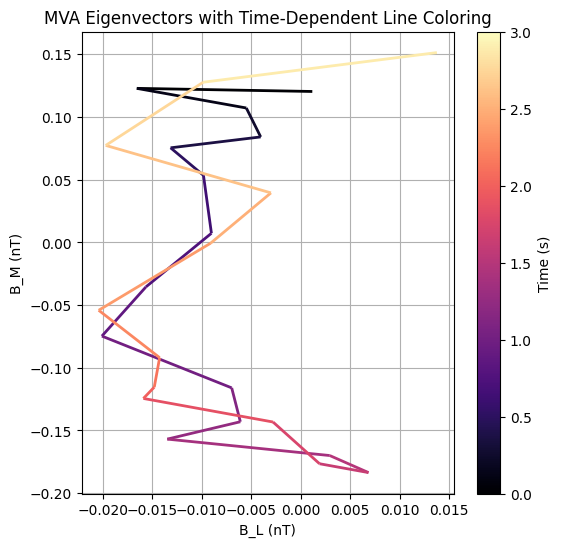

In [31]:
# Prepare the data for the line segments
x, y = filtered_data['B_L'].values, filtered_data['B_M'].values
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='magma', norm=norm)
lc.set_array(time_numeric)  # Use numeric time for color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_M (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()

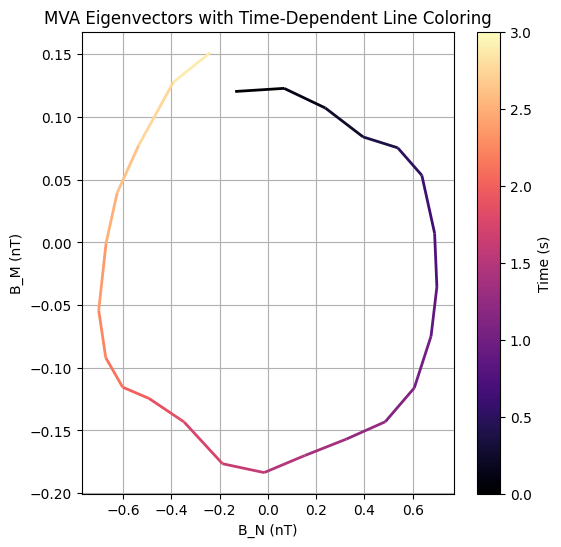

In [32]:
# Prepare the data for the line segments
x, y = filtered_data['B_N'].values, filtered_data['B_M'].values
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='magma', norm=norm)
lc.set_array(time_numeric)  # Use numeric time for color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.set_xlabel('B_N (nT)')
ax.autoscale()
ax.set_ylabel('B_M (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()

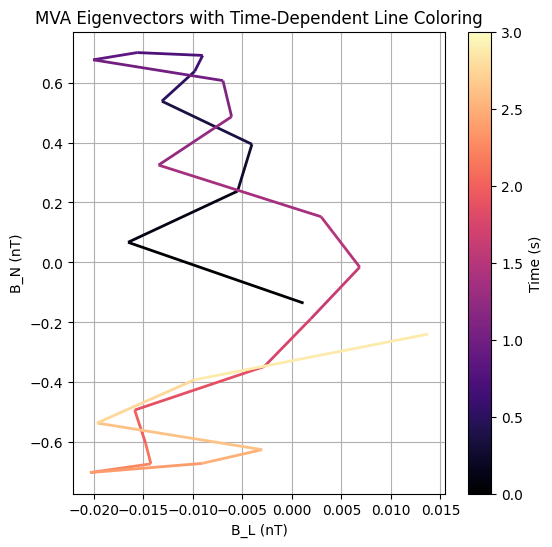

In [33]:
# Prepare the data for the line segments
x, y = filtered_data['B_L'].values, filtered_data['B_N'].values
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

# Create the colormap and normalize time
norm = Normalize(vmin=time_numeric.min(), vmax=time_numeric.max())
lc = LineCollection(segments, cmap='magma', norm=norm)
lc.set_array(time_numeric)  # Use numeric time fr color mapping
lc.set_linewidth(2)

# Plot the line with color gradation
fig, ax = plt.subplots(figsize=(6, 6))
ax.add_collection(lc)
ax.autoscale()
ax.set_xlabel('B_L (nT)')
ax.set_ylabel('B_N (nT)')
ax.set_title('MVA Eigenvectors with Time-Dependent Line Coloring')
plt.colorbar(lc, ax=ax, label='Time (s)')
plt.grid()
plt.show()

In [34]:
eig_vals, eig_vecs = np.linalg.eig(M)
eig_vecs

array([[ 0.92560574,  0.37245071, -0.0673385 ],
       [ 0.12119596, -0.12311337,  0.98496428],
       [-0.35856038,  0.91984975,  0.15909396]])

In [35]:
U, S, _ = np.linalg.svd(M)
eig_vals, eig_vecs = S, U
eig_vecs

array([[-0.92560574,  0.0673385 ,  0.37245071],
       [-0.12119596, -0.98496428, -0.12311337],
       [ 0.35856038, -0.15909396,  0.91984975]])

In [36]:
# Lambda 1 to Lambda 2 ratio
ratio = eig_vals[0] / eig_vals[1]
print(f'λ₁/λ₂ = {ratio:.2f}')


λ₁/λ₂ = 19.93


In [37]:
# Lambda 2 to Lambda 3 ratio
ratio = eig_vals[1] / eig_vals[2]
print(f'λ2/λ3 = {ratio:.2f}')


λ2/λ3 = 166.12


In [38]:
import pandas as pd
from spacepy import pycdf
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt


# Extract the magnetic field data and timestamps
datetime = pd.to_datetime(cdf['Epoch'][:])
b_x = cdf['mms1_fgm_b_gse_srvy_l2'][:, 0]
b_y = cdf['mms1_fgm_b_gse_srvy_l2'][:, 1]
b_z = cdf['mms1_fgm_b_gse_srvy_l2'][:, 2]
b_t = cdf['mms1_fgm_b_gse_srvy_l2'][:, 3]

# Create DataFrame
df = pd.DataFrame({'datetime': datetime, 'b_x': b_x, 'b_y': b_y, 'b_z': b_z, 'b_t': b_t}).set_index('datetime')

# Compute Sampling Frequency
time_diff = np.diff(df.index.astype('int64')) / 1e9  # Convert nanoseconds to seconds
fs = 1 / np.mean(time_diff)  # Hz

# Define Butterworth Low-Pass Filter
def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs  # Nyquist Frequency
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    return filtfilt(b, a, data)  # Use filtfilt for zero-phase filtering

# Apply Low-Pass Filter
cutoff_freq = 0.05  # Hz
df['B0_x'] = butter_lowpass_filter(df['b_x'], cutoff_freq, fs)
df['B0_y'] = butter_lowpass_filter(df['b_y'], cutoff_freq, fs)
df['B0_z'] = butter_lowpass_filter(df['b_z'], cutoff_freq, fs)
df['B0_t'] = butter_lowpass_filter(df['b_t'], cutoff_freq, fs)


# Select the filtered data within the specified time range
start_time = pd.Timestamp('2015-10-28 16:45:03.255000')
end_time = pd.Timestamp('2015-10-28 16:45:06.385000')
# filtered_data = data.loc[start_time:end_time]
# # Define time range
# start_time = pd.Timestamp('2015-10-28 13:00:00')
# end_time = pd.Timestamp('2015-10-28 17:30:00')

# # Filter dataframe for plotting
df_filtered = df.loc[start_time:end_time]



In [39]:
Bx0,By0,Bz0 = np.mean(df_filtered['B0_x']),np.mean(df_filtered['B0_y']),np.mean(df_filtered['B0_z'])
Bx0,By0, Bz0

(np.float64(14.745973326262948),
 np.float64(13.413550681488493),
 np.float64(44.00878574523771))

In [40]:
B0 = np.array([Bx0,By0,Bz0])
K = eig_vecs[:,2]

In [41]:
import numpy as np

# Compute the angle (convert to degrees)
theta = np.degrees(np.arccos(np.dot(K,B0) / (np.linalg.norm(K) * np.linalg.norm(B0))))

print(f"Angle θ between K and B0: {theta:.2f} degrees")


Angle θ between K and B0: 23.45 degrees
